# Phase 3A Step 11 — Comprehensive Outlier Detection and Anomaly Analysis

## Customer Retention Intelligence System

This independent notebook examines statistical rarity and business consistency in the IBM
Telco **development split only**. Detection is exploratory: no record is removed, clipped,
winsorized, transformed, or permanently labelled. No supervised churn model, hypothesis
test, feature selection, class balancing, or production feature engineering is performed.

## 1. Independent setup and leakage-safe loading

The project root is found dynamically and the configured input must be exactly
`data/processed/development.parquet`. Previous notebooks are not imported or executed.
The source checksum is captured before analysis and checked again at the end.

In [1]:
# ruff: noqa: E501
import importlib.metadata as metadata
import sys
from pathlib import Path


def find_project_root(start: Path) -> Path:
    # Find the nearest parent containing project markers.
    start = start.resolve()
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file() and (candidate / "params.yaml").is_file():
            return candidate
    raise FileNotFoundError("Could not locate project root.")


PROJECT_ROOT = find_project_root(Path.cwd())
SRC_PATH = PROJECT_ROOT / "src"
if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

from retention.utils.config import load_config  # noqa: E402

config = load_config(PROJECT_ROOT / "params.yaml")
configured_development_path = Path(config["data"]["development_path"])
assert configured_development_path == Path("data/processed/development.parquet")
development_path = (PROJECT_ROOT / configured_development_path).resolve()
assert development_path.is_file()

print(f"Project root: {PROJECT_ROOT}")
print(f"Input: {configured_development_path}")
print(f"Python: {sys.version.split()[0]} ({sys.executable})")
print(f"Configured random state: {config['project']['random_state']}")
for package in ["pandas", "numpy", "scikit-learn", "matplotlib", "seaborn", "pyarrow"]:
    print(f"{package}: {metadata.version(package)}")

Project root: /Users/harshagarwal/Projects/ChurnRatePredictor
Input: data/processed/development.parquet
Python: 3.11.14 (/Users/harshagarwal/Projects/ChurnRatePredictor/.venv/bin/python)
Configured random state: 42
pandas: 2.3.3
numpy: 2.4.6
scikit-learn: 1.9.1
matplotlib: 3.11.2
seaborn: 0.13.2
pyarrow: 26.0.1


In [2]:
# ruff: noqa: E501
import hashlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from matplotlib.ticker import PercentFormatter
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import RobustScaler

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 300)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.labelsize": 11})

source_sha256_before = hashlib.sha256(development_path.read_bytes()).hexdigest()
df = pd.read_parquet(development_path)
target_column = config["data"]["target_column"]
identifier_column = config["data"]["id_column"]
random_state = int(config["project"]["random_state"])
numerical_features = ["tenure", "MonthlyCharges", "TotalCharges"]
detector_data = df[numerical_features].copy()

assert df.shape == (5_634, 21)
assert detector_data.notna().all().all()
assert target_column not in detector_data and identifier_column not in detector_data
print(f"Development data: {df.shape[0]:,} rows × {df.shape[1]} columns")
print("Detector inputs only:", numerical_features)
print("Source SHA-256:", source_sha256_before)
display(detector_data.describe().T)

Development data: 5,634 rows × 21 columns
Detector inputs only: ['tenure', 'MonthlyCharges', 'TotalCharges']
Source SHA-256: 28d12b92122ab94a8172be83e2bcf7e93b128a1bf3633c2b48075c426864da13


,count,mean,std,min,25%,50%,75%,max
tenure,"5,634.0000",32.3497,24.5826,0.0000,9.0000,29.0000,55.0000,72.0000
MonthlyCharges,"5,634.0000",65.0327,30.0232,18.4000,38.3125,70.5250,89.9000,118.7500
TotalCharges,"5,634.0000","2,291.4303","2,277.1564",0.0000,393.2250,"1,395.5250","3,832.9000","8,684.8000"


# 2. Statistical fundamentals

- An **outlier** is unusually distant under a stated statistical rule. An **anomaly** is a
  broader pattern that departs from an expected global or local structure. **Noise** is
  random variation, while a **data error** is a demonstrably incorrect value or record.
- A **univariate** outlier is extreme in one feature. A **multivariate** outlier may have
  ordinary individual values but an unusual combination. A **global** anomaly is rare
  relative to the full population; a **local** anomaly is unusual only near comparable
  observations.
- Statistical rarity is not business invalidity. A 72-month premium subscriber can be
  rare yet valid; a schema violation can be erroneous without being numerically extreme.
- Extreme observations can pull means, inflate variances, change correlations, and create
  high-leverage regression coefficients. **Masking** occurs when several anomalies hide one
  another by shifting the reference distribution; **swamping** occurs when valid points are
  incorrectly flagged because anomalies distort the rule.

Outliers must not be removed automatically: they may be valid high-value customers,
important churn segments, or the exact cases a production system must handle. Exploratory
detection generates questions. Production treatment requires data lineage, business rules,
fold-fitted transformations, monitoring, and validation against model and decision goals.

# 3. IQR-based outlier detection

For quartiles $Q_1,Q_3$, the interquartile range and fences are

$$IQR=Q_3-Q_1,\qquad L_k=Q_1-kIQR,\qquad U_k=Q_3+kIQR.$$

We inspect $k=1.5$ and conservative outer fences $k=3$. Quartiles resist a small number of
extreme values, so IQR is more robust than mean/standard-deviation rules. However, fixed
fences behave differently for skewed, bounded, discrete, and multimodal distributions.
Box-plot whiskers are statistical conventions—not telecom validity constraints.

In [3]:
# ruff: noqa: E501
def iqr_summary(data: pd.DataFrame, features: list[str], multiplier: float) -> tuple[pd.DataFrame, pd.DataFrame]:
    # Return feature summaries and observation-level flags.
    rows = []
    flags = pd.DataFrame(False, index=data.index, columns=features)
    for feature in features:
        q1, q3 = data[feature].quantile([0.25, 0.75])
        iqr = q3 - q1
        lower_fence, upper_fence = q1 - multiplier * iqr, q3 + multiplier * iqr
        lower = data[feature] < lower_fence
        upper = data[feature] > upper_fence
        flags[feature] = lower | upper
        rows.append({"multiplier": multiplier, "feature": feature, "q1": q1, "q3": q3, "iqr": iqr, "lower_fence": lower_fence, "upper_fence": upper_fence, "lower_count": int(lower.sum()), "upper_count": int(upper.sum()), "flagged_count": int((lower | upper).sum()), "flagged_pct": 100 * (lower | upper).mean()})
    return pd.DataFrame(rows), flags


iqr_15_summary, iqr_15_by_feature = iqr_summary(detector_data, numerical_features, 1.5)
iqr_30_summary, iqr_30_by_feature = iqr_summary(detector_data, numerical_features, 3.0)
iqr_summary_table = pd.concat([iqr_15_summary, iqr_30_summary], ignore_index=True)
iqr_reference_flag = iqr_15_by_feature.any(axis=1)
display(iqr_summary_table)
print(f"Rows flagged by any 1.5×IQR fence: {iqr_reference_flag.sum():,} ({iqr_reference_flag.mean():.2%})")

,multiplier,feature,q1,q3,iqr,lower_fence,upper_fence,lower_count,upper_count,flagged_count,flagged_pct
0,1.5000,tenure,9.0000,55.0000,46.0000,-60.0000,124.0000,0,0,0,0.0000
1,1.5000,MonthlyCharges,38.3125,89.9000,51.5875,-39.0688,167.2812,0,0,0,0.0000
2,1.5000,TotalCharges,393.2250,"3,832.9000","3,439.6750","-4,766.2875","8,992.4125",0,0,0,0.0000
3,3.0000,tenure,9.0000,55.0000,46.0000,-129.0000,193.0000,0,0,0,0.0000
4,3.0000,MonthlyCharges,38.3125,89.9000,51.5875,-116.4500,244.6625,0,0,0,0.0000
5,3.0000,TotalCharges,393.2250,"3,832.9000","3,439.6750","-9,925.8000","14,151.9250",0,0,0,0.0000


Rows flagged by any 1.5×IQR fence: 0 (0.00%)


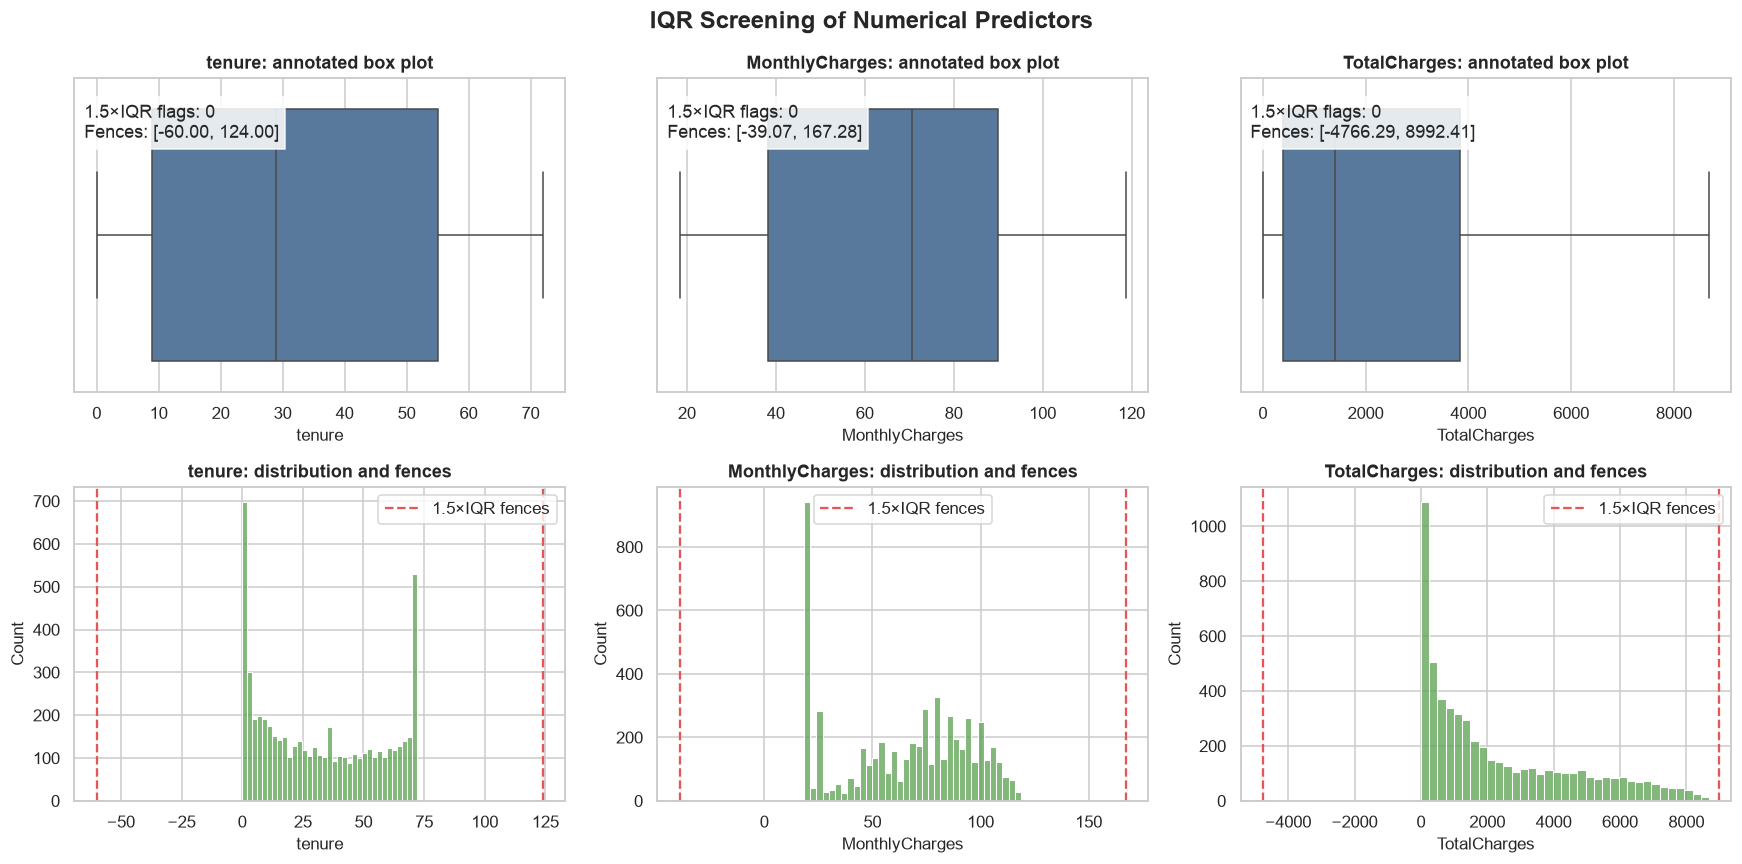

In [4]:
# ruff: noqa: E501
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for column_index, feature in enumerate(numerical_features):
    sns.boxplot(x=detector_data[feature], color="#4C78A8", ax=axes[0, column_index])
    row = iqr_15_summary.set_index("feature").loc[feature]
    axes[0, column_index].set_title(f"{feature}: annotated box plot")
    axes[0, column_index].text(0.02, 0.92, f"1.5×IQR flags: {int(row['flagged_count'])}\nFences: [{row['lower_fence']:.2f}, {row['upper_fence']:.2f}]", transform=axes[0, column_index].transAxes, va="top", bbox={"facecolor": "white", "alpha": 0.85})
    sns.histplot(detector_data[feature], bins=35, color="#59A14F", ax=axes[1, column_index])
    axes[1, column_index].axvline(row["lower_fence"], color="#E45756", linestyle="--", label="1.5×IQR fences")
    axes[1, column_index].axvline(row["upper_fence"], color="#E45756", linestyle="--")
    axes[1, column_index].set_title(f"{feature}: distribution and fences")
    axes[1, column_index].legend()
fig.suptitle("IQR Screening of Numerical Predictors", fontsize=16, fontweight="bold")
fig.tight_layout()
plt.show()

**Observed IQR finding.** Neither the 1.5× nor 3× fences flag any value. The 1.5× upper
fences are 124 months, 167.28 monthly-charge units, and 8,992.41 total-charge units, all
above observed maxima; lower fences are below valid minima. This reflects wide, bounded or
right-skewed distributions—not proof that every record is valid.

# 4. Standard Z-score analysis

The standard score is

$$z_i=\frac{x_i-\bar{x}}{s},$$

using the feature mean and population standard deviation in this descriptive notebook.
Thresholds $|z|>2,2.5,3$ are sensitivity screens. Mean and standard deviation are themselves
sensitive to extremes, and a zero-variance feature is assigned zero scores safely. The
familiar three-sigma probability interpretation requires an approximately normal reference;
it is not valid for these bounded, skewed or multimodal predictors.

,threshold,feature,lower_count,upper_count,flagged_count,flagged_pct
0,2.0000,tenure,0,0,0,0.0000
1,2.0000,MonthlyCharges,0,0,0,0.0000
2,2.0000,TotalCharges,0,315,315,5.5911
3,2.5000,tenure,0,0,0,0.0000
4,2.5000,MonthlyCharges,0,0,0,0.0000
5,2.5000,TotalCharges,0,73,73,1.2957
6,3.0000,tenure,0,0,0,0.0000
7,3.0000,MonthlyCharges,0,0,0,0.0000
8,3.0000,TotalCharges,0,0,0,0.0000


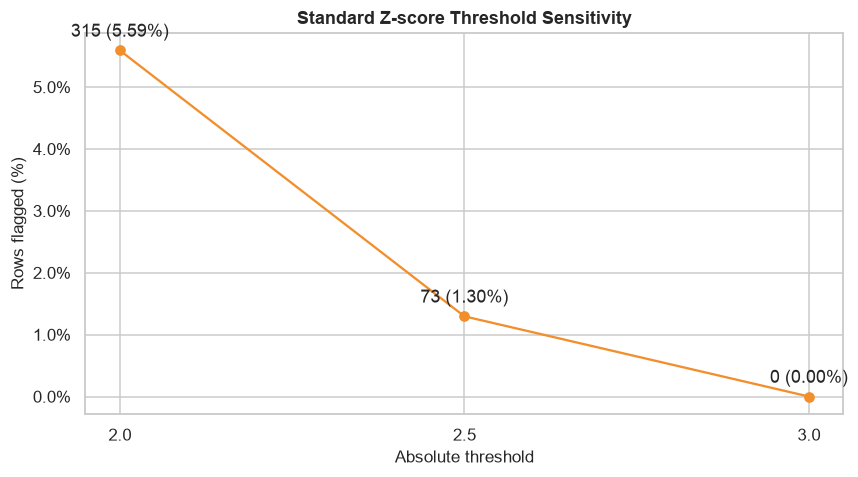

In [5]:
# ruff: noqa: E501
def safe_standard_z(values: pd.Series) -> pd.Series:
    # Return zeros when population standard deviation is zero.
    standard_deviation = values.std(ddof=0)
    if not np.isfinite(standard_deviation) or standard_deviation == 0:
        return pd.Series(0.0, index=values.index)
    return (values - values.mean()) / standard_deviation


standard_z = detector_data.apply(safe_standard_z)
z_rows = []
for threshold in [2.0, 2.5, 3.0]:
    for feature in numerical_features:
        lower = standard_z[feature] < -threshold
        upper = standard_z[feature] > threshold
        z_rows.append({"threshold": threshold, "feature": feature, "lower_count": int(lower.sum()), "upper_count": int(upper.sum()), "flagged_count": int((lower | upper).sum()), "flagged_pct": 100 * (lower | upper).mean()})
z_summary = pd.DataFrame(z_rows)
z_reference_flag = standard_z.abs().gt(3).any(axis=1)
display(z_summary)

z_any = pd.DataFrame({threshold: standard_z.abs().gt(threshold).any(axis=1) for threshold in [2.0, 2.5, 3.0]})
fig, axis = plt.subplots(figsize=(8, 4.5))
(100 * z_any.mean()).plot(marker="o", color="#F28E2B", ax=axis)
axis.set(title="Standard Z-score Threshold Sensitivity", xlabel="Absolute threshold", ylabel="Rows flagged (%)")
axis.set_xticks([2.0, 2.5, 3.0])
axis.yaxis.set_major_formatter(PercentFormatter(xmax=100))
for threshold, percentage in (100 * z_any.mean()).items():
    axis.annotate(f"{int(z_any[threshold].sum())} ({percentage:.2f}%)", (threshold, percentage), xytext=(0, 9), textcoords="offset points", ha="center")
plt.tight_layout()
plt.show()

**Observed Z-score finding.** Only upper-tail TotalCharges values are flagged: 315 rows
(5.59%) at $|z|>2$ and 73 (1.30%) at $|z|>2.5$; no feature exceeds $|z|>3$. Tenure and
MonthlyCharges are bounded tightly enough to produce no flags at any tested threshold.
The collapse from 315 to zero shows that the selected cutoff, not a discovered natural
boundary, drives the classification.

# 5. Modified Z-score and MAD

For median $\tilde{x}$ and median absolute deviation

$$MAD=\operatorname{median}(|x_i-\tilde{x}|),\qquad
M_i=0.67449\frac{x_i-\tilde{x}}{MAD}.$$

The median and MAD are resistant to extreme magnitudes. The constant 0.67449 is the 75th
percentile of a standard normal distribution and makes modified scores roughly comparable
to ordinary Z-scores under normality. We inspect $|M|>3.5$. If MAD is zero, the function
returns zero rather than dividing by zero; such a feature needs a separate discreteness or
frequency analysis. Robustness does not make the rule a business-validity test.

In [6]:
# ruff: noqa: E501
def safe_modified_z(values: pd.Series) -> tuple[pd.Series, float, float]:
    # Return scores, median, and MAD with safe zero-MAD handling.
    median = values.median()
    mad = (values - median).abs().median()
    if not np.isfinite(mad) or mad == 0:
        return pd.Series(0.0, index=values.index), float(median), float(mad)
    return 0.67449 * (values - median) / mad, float(median), float(mad)


modified_z = pd.DataFrame(index=df.index)
modified_rows = []
for feature in numerical_features:
    scores, median, mad = safe_modified_z(detector_data[feature])
    modified_z[feature] = scores
    lower, upper = scores.lt(-3.5), scores.gt(3.5)
    modified_rows.append({"feature": feature, "median": median, "mad": mad, "lower_count": int(lower.sum()), "upper_count": int(upper.sum()), "flagged_count": int((lower | upper).sum()), "flagged_pct": 100 * (lower | upper).mean()})
modified_summary = pd.DataFrame(modified_rows)
modified_reference_flag = modified_z.abs().gt(3.5).any(axis=1)
display(modified_summary)

univariate_reference_comparison = pd.DataFrame({
    "1.5×IQR": iqr_reference_flag,
    "|Z| > 3": z_reference_flag,
    "|modified Z| > 3.5": modified_reference_flag,
}).sum().rename("flagged_rows").to_frame()
display(univariate_reference_comparison)

,feature,median,mad,lower_count,upper_count,flagged_count,flagged_pct
0,tenure,29.0000,23.0000,0,0,0,0.0000
1,MonthlyCharges,70.5250,23.8250,0,0,0,0.0000
2,TotalCharges,"1,395.5250","1,227.1750",0,112,112,1.9879


,flagged_rows
1.5×IQR,0
|Z| > 3,0
|modified Z| > 3.5,112


**Observed modified-Z finding.** Tenure MAD is 23 months, MonthlyCharges MAD is 23.825,
and TotalCharges MAD is 1,227.175. Only 112 upper-tail TotalCharges observations (1.99%)
exceed 3.5. Thus robust median/MAD scaling flags accumulated-spend extremes that 1.5×IQR
and $|Z|>3$ do not. This is a method-definition difference, not confirmation of error.

# 6. Percentile-based extreme-value analysis

Percentile screens define tails by empirical rank. We inspect values **strictly beyond**
the 1st/99th and 5th/95th percentiles. These are extreme-value labels by design, not anomaly
proof. Ties can make the actual flagged percentage smaller than the nominal tail mass; for
bounded tenure, both the 95th and 99th percentiles equal the 72-month ceiling, so ceiling
customers are not strictly above either threshold. No winsorization, clipping, or removal
is performed.

,percentiles,feature,lower_threshold,upper_threshold,lower_count,upper_count,flagged_count,flagged_pct
0,1%/99%,tenure,1.0000,72.0000,10,0,10,0.1775
1,1%/99%,MonthlyCharges,19.2000,114.9835,54,57,111,1.9702
2,1%/99%,TotalCharges,19.7500,"8,064.2805",53,57,110,1.9524
3,5%/95%,tenure,1.0000,72.0000,10,0,10,0.1775
4,5%/95%,MonthlyCharges,19.6500,107.5675,260,282,542,9.6202
5,5%/95%,TotalCharges,48.6975,"6,975.7750",282,282,564,10.0106


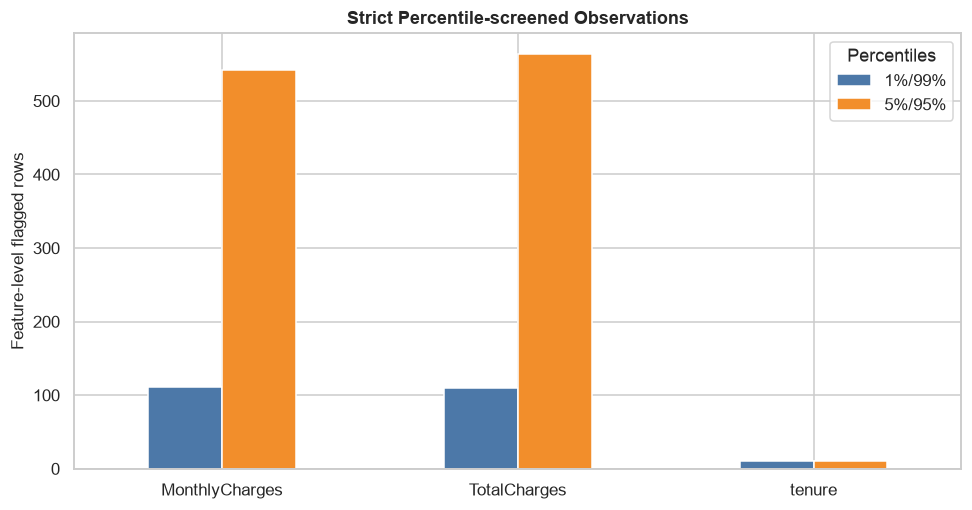

In [7]:
# ruff: noqa: E501
percentile_rows = []
percentile_flags = {}
for lower_q, upper_q in [(0.01, 0.99), (0.05, 0.95)]:
    per_feature = pd.DataFrame(False, index=df.index, columns=numerical_features)
    for feature in numerical_features:
        lower_value, upper_value = detector_data[feature].quantile([lower_q, upper_q])
        lower, upper = detector_data[feature].lt(lower_value), detector_data[feature].gt(upper_value)
        per_feature[feature] = lower | upper
        percentile_rows.append({"percentiles": f"{lower_q:.0%}/{upper_q:.0%}", "feature": feature, "lower_threshold": lower_value, "upper_threshold": upper_value, "lower_count": int(lower.sum()), "upper_count": int(upper.sum()), "flagged_count": int((lower | upper).sum()), "flagged_pct": 100 * (lower | upper).mean()})
    percentile_flags[(lower_q, upper_q)] = per_feature.any(axis=1)
percentile_summary = pd.DataFrame(percentile_rows)
percentile_reference_flag = percentile_flags[(0.01, 0.99)]
display(percentile_summary)

fig, axis = plt.subplots(figsize=(9, 4.8))
plot_percentiles = percentile_summary.pivot(index="feature", columns="percentiles", values="flagged_count")
plot_percentiles.plot.bar(ax=axis, color=["#4C78A8", "#F28E2B"])
axis.set(title="Strict Percentile-screened Observations", xlabel="", ylabel="Feature-level flagged rows")
axis.tick_params(axis="x", rotation=0)
axis.legend(title="Percentiles")
plt.tight_layout()
plt.show()

**Observed percentile finding.** The strict 1%/99% screen flags 10 tenure, 111
MonthlyCharges, and 110 TotalCharges values; their union is 179 rows (3.18%). The strict
5%/95% union is 882 rows (15.65%). Tenure contributes only ten zero-month observations
because ties at 1 and 72 months are not beyond the percentile values. Legitimate premium
and newly enrolled customers are deliberately included in these empirical tails.

# 7. Domain-driven anomaly analysis

The exploratory benchmark $tenure\times MonthlyCharges$ uses the **current** monthly price,
not historical invoices. We calculate

$$D=TotalCharges-(tenure\times MonthlyCharges),\qquad
\overline{Charge}_{history}=\frac{TotalCharges}{tenure}\quad(tenure>0).$$

Division by zero produces `NaN`, not infinity. Pricing changes, introductory discounts,
partial periods, bundles, credits, taxes, and billing adjustments can produce differences.
Billing history is unavailable, so deviations are unexplained patterns—not confirmed errors.

In [8]:
# ruff: noqa: E501
domain_analysis = detector_data.copy()
domain_analysis["tenure_x_monthly"] = domain_analysis["tenure"] * domain_analysis["MonthlyCharges"]
domain_analysis["total_minus_tenure_x_monthly"] = domain_analysis["TotalCharges"] - domain_analysis["tenure_x_monthly"]
domain_analysis["average_historical_charge"] = np.where(domain_analysis["tenure"].gt(0), domain_analysis["TotalCharges"] / domain_analysis["tenure"], np.nan)

domain_counts = pd.Series({
    "zero_tenure": df["tenure"].eq(0).sum(),
    "zero_total_charges": df["TotalCharges"].eq(0).sum(),
    "zero_tenure_and_zero_total": (df["tenure"].eq(0) & df["TotalCharges"].eq(0)).sum(),
    "tenure_72_ceiling": df["tenure"].eq(72).sum(),
    "above_monthly_charge_p99": df["MonthlyCharges"].gt(df["MonthlyCharges"].quantile(0.99)).sum(),
    "above_total_charge_p99": df["TotalCharges"].gt(df["TotalCharges"].quantile(0.99)).sum(),
}, name="customer_count")
display(domain_counts.to_frame())
display(domain_analysis[["tenure_x_monthly", "total_minus_tenure_x_monthly", "average_historical_charge"]].describe(percentiles=[0.01, 0.05, 0.50, 0.95, 0.99]).T)

largest_billing_differences = df[[identifier_column] + numerical_features].join(domain_analysis[["tenure_x_monthly", "total_minus_tenure_x_monthly", "average_historical_charge"]]).loc[domain_analysis["total_minus_tenure_x_monthly"].abs().nlargest(10).index]
display(largest_billing_differences)

,customer_count
zero_tenure,10
zero_total_charges,10
zero_tenure_and_zero_total,10
tenure_72_ceiling,299
above_monthly_charge_p99,57
above_total_charge_p99,57


,count,mean,std,min,1%,5%,50%,95%,99%,max
tenure_x_monthly,"5,634.0000","2,291.5666","2,275.8553",0.0000,19.7500,48.5475,"1,392.6000","6,969.6800","8,067.6690","8,550.0000"
total_minus_tenure_x_monthly,"5,634.0000",-0.1363,67.2744,-370.8500,-191.9420,-113.8200,0.0000,111.6350,188.6500,373.2500
average_historical_charge,"5,624.0000",65.1050,30.1091,13.8286,17.6376,19.3630,70.6261,107.9523,115.3880,121.4000


,customerID,tenure,MonthlyCharges,TotalCharges,tenure_x_monthly,total_minus_tenure_x_monthly,average_historical_charge
1161,9350-VLHMB,67,89.5500,"6,373.1000","5,999.8500",373.2500,95.1209
4181,3963-RYFNS,72,116.4500,"8,013.5500","8,384.4000",-370.8500,111.2993
1900,0083-PIVIK,64,81.2500,"5,567.5500","5,200.0000",367.5500,86.9930
5205,0266-CLZKZ,67,105.6500,"6,717.9000","7,078.5500",-360.6500,100.2672
818,4612-THJBS,56,104.7500,"5,510.6500","5,866.0000",-355.3500,98.4045
4271,0895-DQHEW,54,104.3000,"5,278.1500","5,632.2000",-354.0500,97.7435
1520,7176-WRTNX,70,114.9500,"7,711.2500","8,046.5000",-335.2500,110.1607
876,8879-XUAHX,71,116.2500,"8,564.7500","8,253.7500",311.0000,120.6303
746,2235-EZAIK,72,79.2000,"5,401.9000","5,702.4000",-300.5000,75.0264
2865,0052-DCKON,66,115.8000,"7,942.1500","7,642.8000",299.3500,120.3356


,violations
phone_service_state_inconsistency,0
internet_service_state_inconsistency,0
zero_tenure_nonzero_total,0
positive_tenure_zero_total,0
nonpositive_monthly_charge,0
negative_total_charge,0


tenure                 MonthlyCharges          \
                              count min  median max          count     min   
InternetService PhoneService                                                 
DSL             No              529   0 28.0000  72            529 23.4500   
                Yes            1405   0 30.0000  72           1405 42.9000   
Fiber optic     Yes            2493   1 30.0000  72           2493 67.7500   
No              Yes            1207   0 25.0000  72           1207 18.4000   

                                              TotalCharges                     \
                              median      max        count     min     median   
InternetService PhoneService                                                    
DSL             No           40.6500  67.2000          529  0.0000 1,147.0000   
                Yes          64.0000  94.8000         1405  0.0000 1,924.1000   
Fiber optic     Yes          91.8500 118.7500         2493 68.5000 2,673.4500   
No              Yes          20.1000  26.9000         1207  0.0000   507.4000   

                                         
                                    max  
InternetService PhoneService             
DSL             No           4,919.7000  
                Yes          6,859.0500  
Fiber optic     Yes          8,684.8000  
No              Yes          2,006.9500

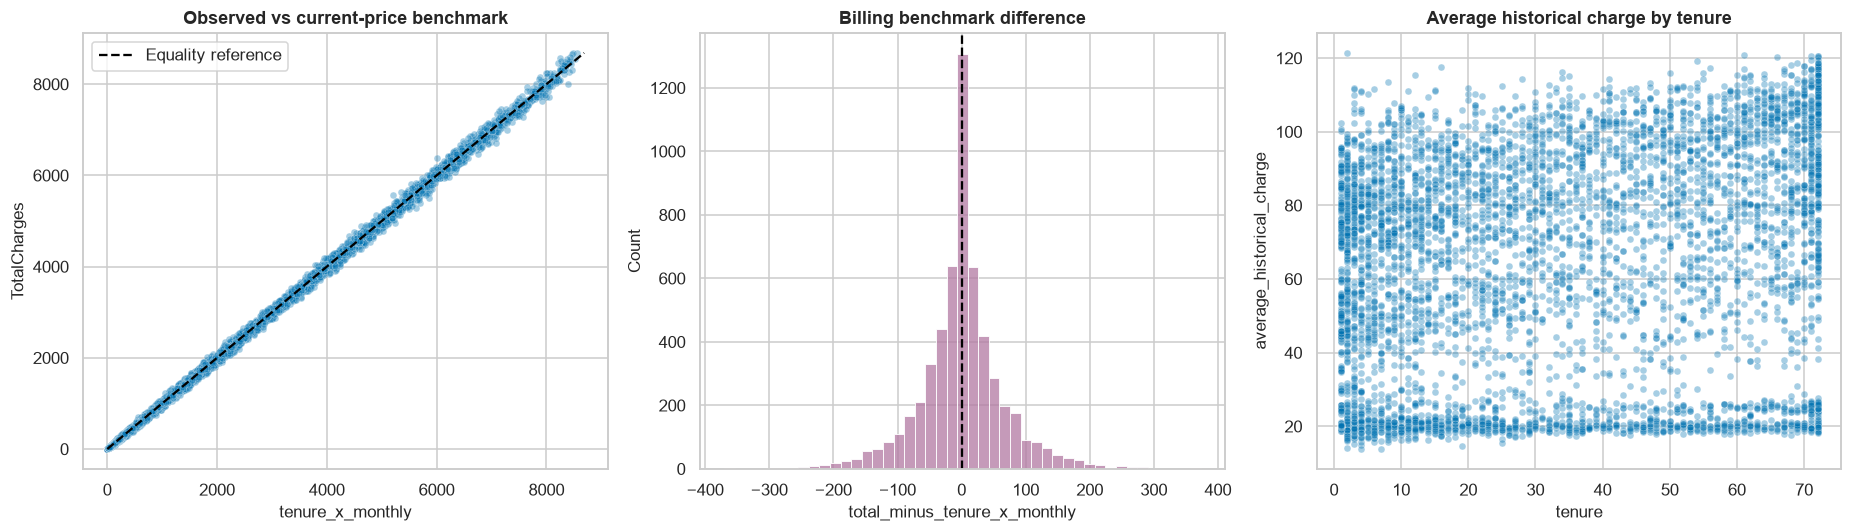

In [9]:
# ruff: noqa: E501
internet_addons = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
phone_inconsistency = ((df["PhoneService"] == "No") & (df["MultipleLines"] != "No phone service")) | ((df["PhoneService"] == "Yes") & (df["MultipleLines"] == "No phone service"))
internet_inconsistency = pd.Series(False, index=df.index)
for feature in internet_addons:
    internet_inconsistency |= ((df["InternetService"] == "No") & (df[feature] != "No internet service")) | ((df["InternetService"] != "No") & (df[feature] == "No internet service"))

consistency_checks = pd.Series({
    "phone_service_state_inconsistency": phone_inconsistency.sum(),
    "internet_service_state_inconsistency": internet_inconsistency.sum(),
    "zero_tenure_nonzero_total": ((df["tenure"] == 0) & (df["TotalCharges"] != 0)).sum(),
    "positive_tenure_zero_total": ((df["tenure"] > 0) & (df["TotalCharges"] == 0)).sum(),
    "nonpositive_monthly_charge": df["MonthlyCharges"].le(0).sum(),
    "negative_total_charge": df["TotalCharges"].lt(0).sum(),
}, name="violations")
display(consistency_checks.to_frame())
display(df.groupby(["InternetService", "PhoneService"], observed=True)[numerical_features].agg(["count", "min", "median", "max"]))

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
sns.scatterplot(data=domain_analysis, x="tenure_x_monthly", y="TotalCharges", alpha=0.35, s=20, ax=axes[0])
limits = [0, max(domain_analysis["tenure_x_monthly"].max(), domain_analysis["TotalCharges"].max())]
axes[0].plot(limits, limits, linestyle="--", color="black", label="Equality reference")
axes[0].legend()
axes[0].set_title("Observed vs current-price benchmark")
sns.histplot(domain_analysis["total_minus_tenure_x_monthly"], bins=45, color="#B279A2", ax=axes[1])
axes[1].axvline(0, color="black", linestyle="--")
axes[1].set_title("Billing benchmark difference")
sns.scatterplot(data=domain_analysis, x="tenure", y="average_historical_charge", alpha=0.35, s=20, ax=axes[2])
axes[2].set_title("Average historical charge by tenure")
fig.tight_layout()
plt.show()

**Observed domain findings.** All ten zero-tenure customers also have zero TotalCharges;
no positive-tenure customer has zero totals. There are 299 customers (5.31%) at the
72-month ceiling, 57 above each charge feature's 99th percentile, and no tested phone,
internet-service, sign, or zero-total consistency violation. The billing difference has
median 0, mean $-0.14$, standard deviation 67.27, and range $-370.85$ to $373.25$. These
modest differences relative to multi-year totals are compatible with unavailable price
history and are not confirmed schema errors.

# 8. Multivariate anomaly detection

**Isolation Forest** recursively selects features and split values; points isolated in
shorter paths receive more anomalous scores. It handles scale largely through within-feature
random splits, so scaling is generally unnecessary. We use 300 trees, all three numerical
features, configured seed 42, and contamination 1%, 2%, and 5%.

**Local Outlier Factor (LOF)** compares local reachability density with neighbors. A point
is unusual when its density is substantially lower than its neighborhood. Euclidean
distance is scale-sensitive, so a temporary `RobustScaler` centers each feature by its
median and scales by IQR. We inspect 10, 20, and 35 neighbors with the same contaminations.

Contamination specifies how many observations the fitted score threshold labels; it is a
scenario assumption, not estimated anomaly prevalence. Neither detector sees customerID,
Churn, or other predictors, and no fitted object or transformed data is saved.

In [10]:
# ruff: noqa: E501
contaminations = [0.01, 0.02, 0.05]
isolation_flags, isolation_scores = {}, {}
detector_rows = []
for contamination in contaminations:
    model = IsolationForest(n_estimators=300, contamination=contamination, random_state=random_state, n_jobs=-1)
    prediction = model.fit_predict(detector_data)
    isolation_flags[contamination] = pd.Series(prediction == -1, index=df.index)
    isolation_scores[contamination] = pd.Series(-model.score_samples(detector_data), index=df.index)
    detector_rows.append({"detector": "Isolation Forest", "neighbors": np.nan, "contamination": contamination, "flagged_count": int(isolation_flags[contamination].sum()), "flagged_pct": 100 * isolation_flags[contamination].mean()})

scaler = RobustScaler()
lof_input = scaler.fit_transform(detector_data)
lof_flags, lof_scores = {}, {}
for neighbors in [10, 20, 35]:
    for contamination in contaminations:
        model = LocalOutlierFactor(n_neighbors=neighbors, contamination=contamination)
        prediction = model.fit_predict(lof_input)
        lof_flags[(neighbors, contamination)] = pd.Series(prediction == -1, index=df.index)
        lof_scores[(neighbors, contamination)] = pd.Series(-model.negative_outlier_factor_, index=df.index)
        detector_rows.append({"detector": "LOF", "neighbors": neighbors, "contamination": contamination, "flagged_count": int(lof_flags[(neighbors, contamination)].sum()), "flagged_pct": 100 * lof_flags[(neighbors, contamination)].mean()})

detector_sensitivity = pd.DataFrame(detector_rows)
isolation_reference_flag = isolation_flags[0.02]
lof_reference_flag = lof_flags[(20, 0.02)]
display(detector_sensitivity)

,detector,neighbors,contamination,flagged_count,flagged_pct
0,Isolation Forest,NaN,0.0100,57,1.0117
1,Isolation Forest,NaN,0.0200,113,2.0057
2,Isolation Forest,NaN,0.0500,282,5.0053
3,LOF,10.0000,0.0100,57,1.0117
4,LOF,10.0000,0.0200,113,2.0057
5,LOF,10.0000,0.0500,282,5.0053
6,LOF,20.0000,0.0100,57,1.0117
7,LOF,20.0000,0.0200,113,2.0057
8,LOF,20.0000,0.0500,282,5.0053
9,LOF,35.0000,0.0100,57,1.0117


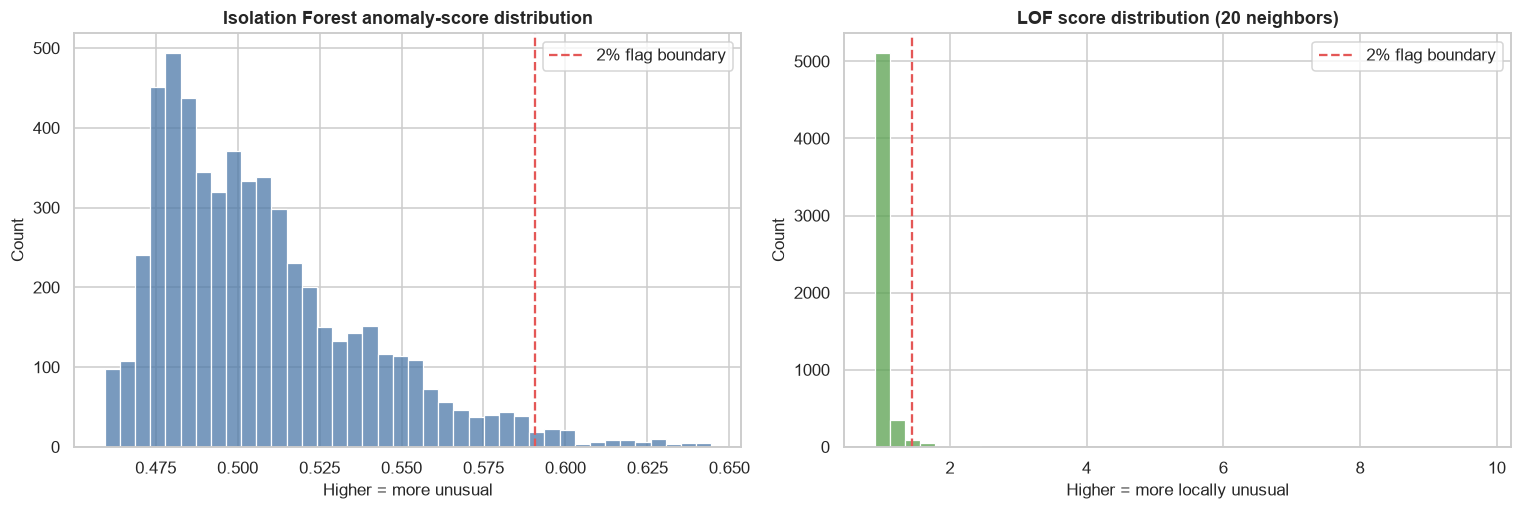

,10,20,35
10,1.0000,0.3951,0.1472
20,0.3951,1.0000,0.3140
35,0.1472,0.3140,1.0000


In [11]:
# ruff: noqa: E501
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
sns.histplot(isolation_scores[0.02], bins=40, color="#4C78A8", ax=axes[0])
axes[0].axvline(isolation_scores[0.02][isolation_reference_flag].min(), color="#E45756", linestyle="--", label="2% flag boundary")
axes[0].set(title="Isolation Forest anomaly-score distribution", xlabel="Higher = more unusual")
axes[0].legend()
sns.histplot(lof_scores[(20, 0.02)], bins=40, color="#59A14F", ax=axes[1])
axes[1].axvline(lof_scores[(20, 0.02)][lof_reference_flag].min(), color="#E45756", linestyle="--", label="2% flag boundary")
axes[1].set(title="LOF score distribution (20 neighbors)", xlabel="Higher = more locally unusual")
axes[1].legend()
fig.tight_layout()
plt.show()

lof_neighbor_jaccard = pd.DataFrame(index=[10, 20, 35], columns=[10, 20, 35], dtype=float)
for left in lof_neighbor_jaccard.index:
    for right in lof_neighbor_jaccard.columns:
        left_flag, right_flag = lof_flags[(left, 0.02)], lof_flags[(right, 0.02)]
        lof_neighbor_jaccard.loc[left, right] = (left_flag & right_flag).sum() / (left_flag | right_flag).sum()
display(lof_neighbor_jaccard)

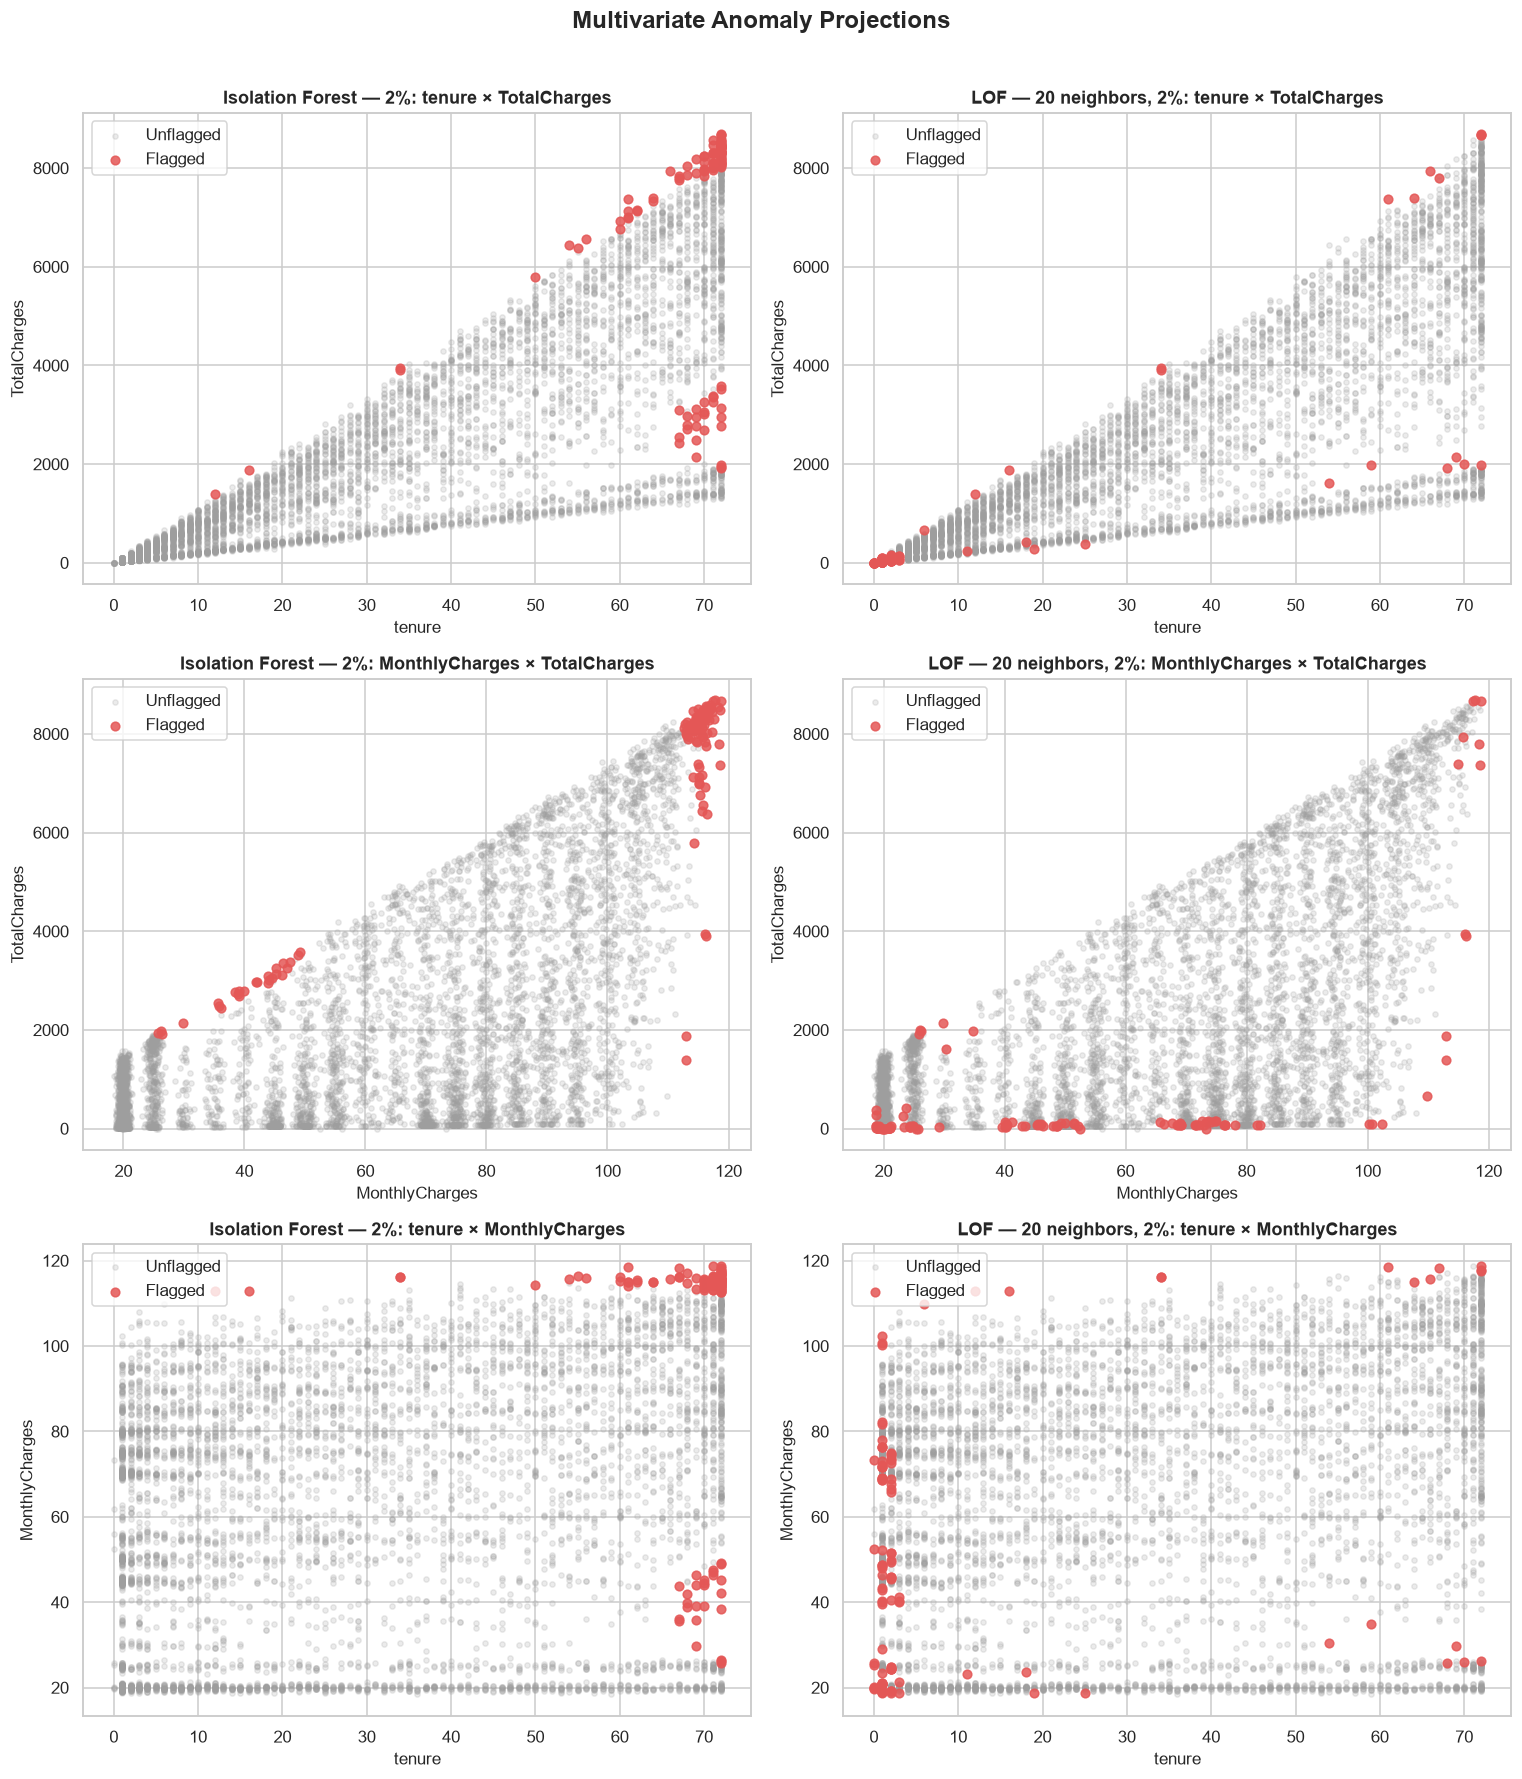

tenure  MonthlyCharges  TotalCharges
group                    statistic                                       
Isolation Forest flagged count     113.0000        113.0000      113.0000
                         mean       67.7345         98.1044    6,638.6535
                         50%        71.0000        115.0000    8,013.5500
                         min        12.0000         25.7000    1,384.7500
                         max        72.0000        118.7500    8,684.8000
LOF flagged              count     113.0000        113.0000      113.0000
                         mean       10.2920         51.2885      767.4420
                         50%         1.0000         45.4000       71.6500
                         min         0.0000         18.7000        0.0000
                         max        72.0000        118.7500    8,684.8000

In [12]:
# ruff: noqa: E501
feature_pairs = [("tenure", "TotalCharges"), ("MonthlyCharges", "TotalCharges"), ("tenure", "MonthlyCharges")]
fig, axes = plt.subplots(3, 2, figsize=(14, 16))
for row_index, (x_feature, y_feature) in enumerate(feature_pairs):
    for column_index, (name, flag) in enumerate([("Isolation Forest — 2%", isolation_reference_flag), ("LOF — 20 neighbors, 2%", lof_reference_flag)]):
        axis = axes[row_index, column_index]
        axis.scatter(df.loc[~flag, x_feature], df.loc[~flag, y_feature], s=12, alpha=0.20, color="#9E9E9E", label="Unflagged")
        axis.scatter(df.loc[flag, x_feature], df.loc[flag, y_feature], s=32, alpha=0.85, color="#E45756", label="Flagged")
        axis.set(xlabel=x_feature, ylabel=y_feature, title=f"{name}: {x_feature} × {y_feature}")
        axis.legend()
fig.suptitle("Multivariate Anomaly Projections", fontsize=16, fontweight="bold", y=1.01)
fig.tight_layout()
plt.show()

reference_detector_profiles = pd.concat({
    "Isolation Forest flagged": detector_data[isolation_reference_flag].describe().loc[["count", "mean", "50%", "min", "max"]],
    "LOF flagged": detector_data[lof_reference_flag].describe().loc[["count", "mean", "50%", "min", "max"]],
}, names=["group", "statistic"])
display(reference_detector_profiles)

**Observed detector findings.** Contamination produces 57, 113, and 282 flags at the 1%,
2%, and 5% scenarios for both algorithms. At the 2% reference, Isolation Forest flags
long-tenure, premium combinations (median tenure 71, MonthlyCharges 115, TotalCharges
8,013.55); 51 of 299 ceiling-tenure customers are included. LOF flags locally sparse
combinations (median tenure 1, MonthlyCharges 45.40, TotalCharges 71.65), including 8 of
10 zero-tenure and 49 of 497 one-month customers.

Only 13 reference flags overlap (Jaccard 0.061). LOF's 2% sets are sensitive to neighborhood
size: Jaccard is 0.395 for 10 versus 20 neighbors, 0.314 for 20 versus 35, and 0.147 for
10 versus 35. This is expected because “local” depends on neighborhood scale.

# 9. Outlier-detection method comparison

Reference flags are fixed without Churn: 1.5×IQR, $|Z|>3$, $|M|>3.5$, strict 1%/99%,
Isolation Forest at 2%, and LOF with 20 neighbors at 2%. For flag sets $A,B$,

$$J(A,B)=\frac{|A\cap B|}{|A\cup B|}.$$

Pairwise raw agreement counts both jointly flagged and jointly unflagged rows, so it can be
misleadingly high for rare flags. Jaccard focuses on flagged-set overlap. Agreement still
does not establish a genuine error; methods can agree on a valid boundary segment.

In [13]:
# ruff: noqa: E501
method_flags = pd.DataFrame({
    "IQR 1.5×": iqr_reference_flag,
    "Standard Z > 3": z_reference_flag,
    "Modified Z > 3.5": modified_reference_flag,
    "Percentile 1/99": percentile_reference_flag,
    "Isolation Forest 2%": isolation_reference_flag,
    "LOF 2%": lof_reference_flag,
})
flag_multiplicity = method_flags.sum(axis=1)
method_comparison = pd.DataFrame({
    "method_type": ["Univariate", "Univariate", "Univariate", "Univariate", "Multivariate global", "Multivariate local"],
    "flagged_count": method_flags.sum().astype(int),
    "flagged_pct": 100 * method_flags.mean(),
}).sort_values("flagged_count", ascending=False)
display(method_comparison)
display(flag_multiplicity.value_counts().sort_index().rename("rows").to_frame())
print(f"Flagged by ≥2 methods: {(flag_multiplicity >= 2).sum():,}")
print(f"Flagged by ≥3 methods: {(flag_multiplicity >= 3).sum():,}")
print(f"Flagged by any method: {method_flags.any(axis=1).sum():,}")

agreement = pd.DataFrame(index=method_flags.columns, columns=method_flags.columns, dtype=float)
jaccard = agreement.copy()
for left in method_flags:
    for right in method_flags:
        agreement.loc[left, right] = method_flags[left].eq(method_flags[right]).mean()
        union = (method_flags[left] | method_flags[right]).sum()
        jaccard.loc[left, right] = (method_flags[left] & method_flags[right]).sum() / union if union else 1.0
display(jaccard)

,method_type,flagged_count,flagged_pct
Percentile 1/99,Univariate,179,3.1771
Isolation Forest 2%,Multivariate global,113,2.0057
LOF 2%,Multivariate local,113,2.0057
Modified Z > 3.5,Univariate,112,1.9879
IQR 1.5×,Univariate,0,0.0000
Standard Z > 3,Univariate,0,0.0000


,rows
0,5298
1,223
2,50
3,58
4,5


Flagged by ≥2 methods: 113
Flagged by ≥3 methods: 63
Flagged by any method: 336


,IQR 1.5×,Standard Z > 3,Modified Z > 3.5,Percentile 1/99,Isolation Forest 2%,LOF 2%
IQR 1.5×,1.0000,1.0000,0.0000,0.0000,0.0000,0.0000
Standard Z > 3,1.0000,1.0000,0.0000,0.0000,0.0000,0.0000
Modified Z > 3.5,0.0000,0.0000,1.0000,0.2819,0.4331,0.0227
Percentile 1/99,0.0000,0.0000,0.2819,1.0000,0.3394,0.1145
Isolation Forest 2%,0.0000,0.0000,0.4331,0.3394,1.0000,0.0610
LOF 2%,0.0000,0.0000,0.0227,0.1145,0.0610,1.0000


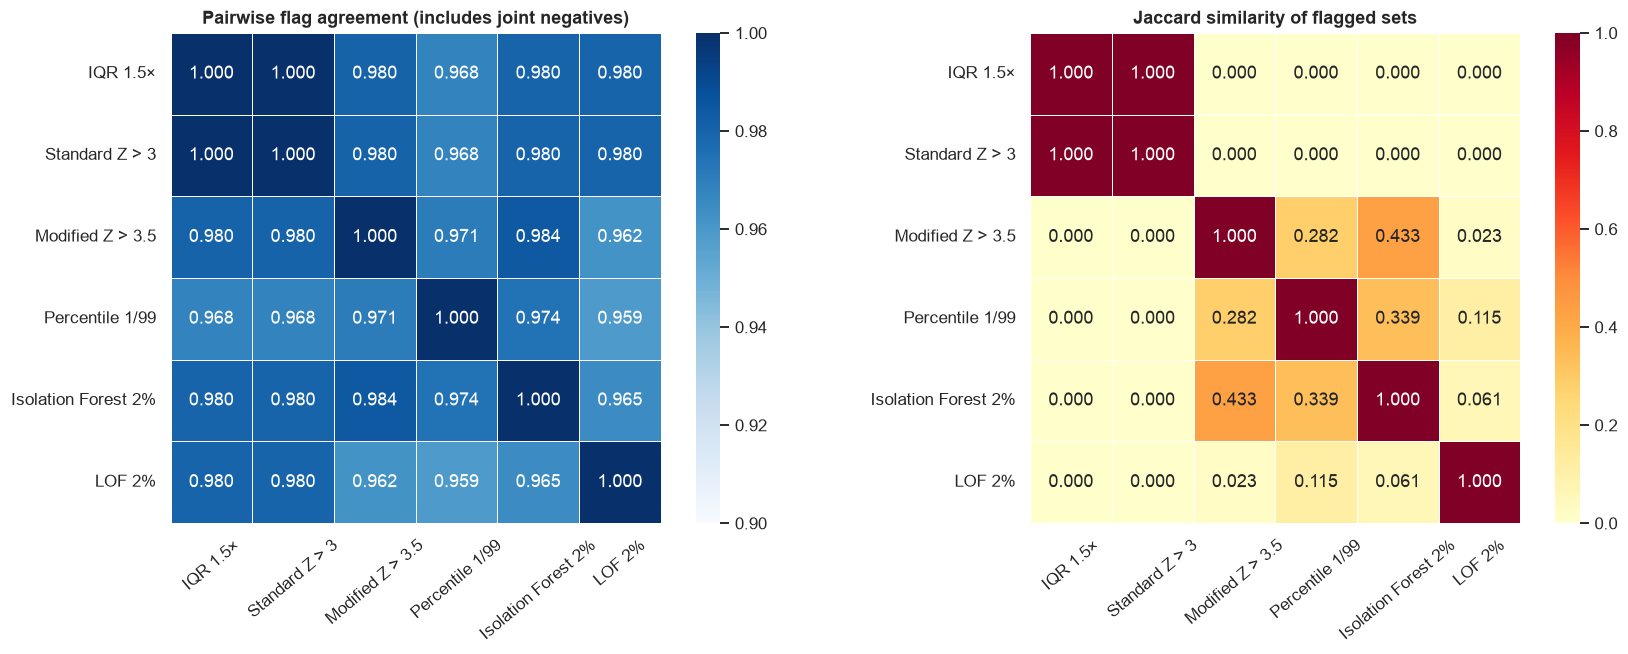

In [14]:
# ruff: noqa: E501
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(agreement, annot=True, fmt=".3f", cmap="Blues", vmin=0.90, vmax=1, square=True, linewidths=0.5, ax=axes[0])
axes[0].set_title("Pairwise flag agreement (includes joint negatives)")
sns.heatmap(jaccard, annot=True, fmt=".3f", cmap="YlOrRd", vmin=0, vmax=1, square=True, linewidths=0.5, ax=axes[1])
axes[1].set_title("Jaccard similarity of flagged sets")
for axis in axes:
    axis.tick_params(axis="x", rotation=40)
    axis.tick_params(axis="y", rotation=0)
fig.tight_layout()
plt.show()

**Observed method comparison.** Counts are 0 IQR, 0 standard-Z, 112 modified-Z, 179
percentile, 113 Isolation Forest, and 113 LOF. The union contains 336 customers; 113 are
flagged by at least two methods and 63 by at least three. Modified-Z/Isolation Forest has
the largest nontrivial Jaccard (0.433), followed by percentile/Isolation Forest (0.339) and
modified-Z/percentile (0.282). LOF overlaps weakly with every global/tail method, reinforcing
the distinction between local multivariate rarity and univariate extremes. The two empty
methods have Jaccard 1 by the explicit empty-set convention, not because they identify cases.

# 10. Outliers and churn — post-detection descriptive audit

Only now, after all detector settings and flags are fixed, is Churn joined for descriptive
comparison. No threshold is optimized using labels. For method $m$, we report
$P(Churn=Yes\mid Flag_m)$, the corresponding unflagged rate, counts by outcome, and the
share of all churners flagged. Groups below 30 are marked small; empty rates remain missing.
An anomaly detector is not a churn classifier.

,flagged_n,small_group_n_lt_30,flagged_churned,flagged_retained,flagged_churn_rate,unflagged_churn_rate,share_of_all_churners_flagged
method,,,,,,,
IQR 1.5×,0,True,0,0,NaN,0.2654,0.0000
Standard Z > 3,0,True,0,0,NaN,0.2654,0.0000
Modified Z > 3.5,112,False,6,106,0.0536,0.2696,0.0040
Percentile 1/99,179,False,20,159,0.1117,0.2704,0.0134
Isolation Forest 2%,113,False,7,106,0.0619,0.2695,0.0047
LOF 2%,113,False,54,59,0.4779,0.2610,0.0361
At least 2 methods,113,False,8,105,0.0708,0.2693,0.0054
Any method,336,False,73,263,0.2173,0.2684,0.0488


Overall development churn rate: 26.54% (1,495/5,634)


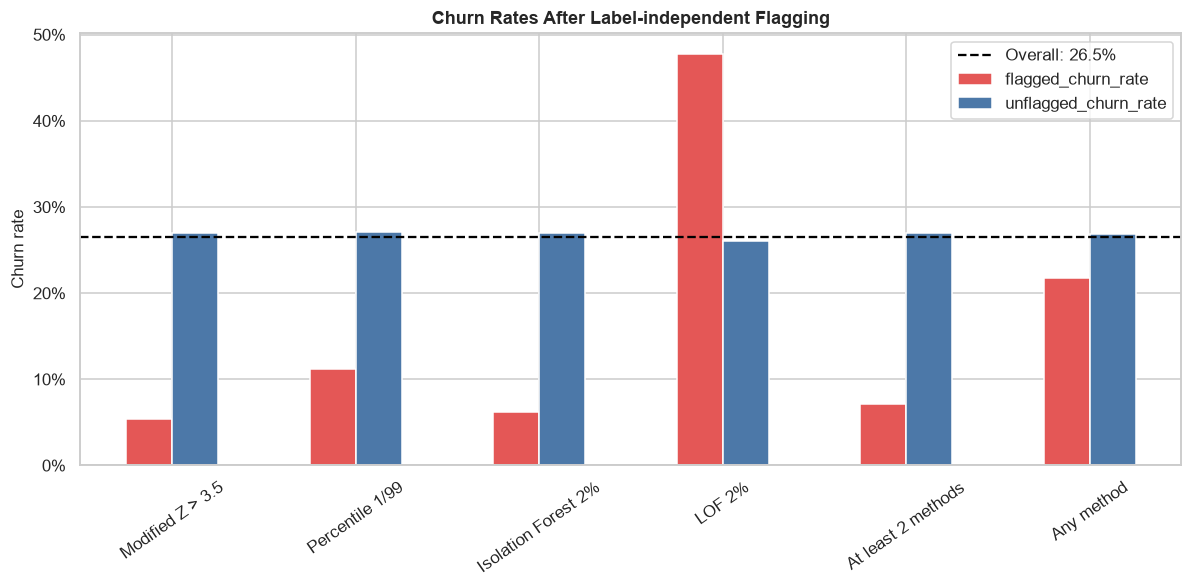

In [15]:
# ruff: noqa: E501
churn_binary = df[target_column].eq("Yes")
overall_churn_rate = churn_binary.mean()
churn_rows = []
churn_flag_sets = {**{column: method_flags[column] for column in method_flags}, "At least 2 methods": flag_multiplicity.ge(2), "Any method": method_flags.any(axis=1)}
for method, flag in churn_flag_sets.items():
    flagged_count = int(flag.sum())
    flagged_churned = int((flag & churn_binary).sum())
    flagged_retained = int((flag & ~churn_binary).sum())
    churn_rows.append({
        "method": method,
        "flagged_n": flagged_count,
        "small_group_n_lt_30": flagged_count < 30,
        "flagged_churned": flagged_churned,
        "flagged_retained": flagged_retained,
        "flagged_churn_rate": flagged_churned / flagged_count if flagged_count else np.nan,
        "unflagged_churn_rate": churn_binary[~flag].mean(),
        "share_of_all_churners_flagged": flagged_churned / churn_binary.sum(),
    })
churn_comparison = pd.DataFrame(churn_rows).set_index("method")
display(churn_comparison)
print(f"Overall development churn rate: {overall_churn_rate:.2%} ({churn_binary.sum():,}/{len(df):,})")

plot_churn = churn_comparison.dropna(subset=["flagged_churn_rate"])[["flagged_churn_rate", "unflagged_churn_rate"]]
fig, axis = plt.subplots(figsize=(11, 5.5))
plot_churn.plot.bar(ax=axis, color=["#E45756", "#4C78A8"])
axis.axhline(overall_churn_rate, color="black", linestyle="--", label=f"Overall: {overall_churn_rate:.1%}")
axis.set(title="Churn Rates After Label-independent Flagging", xlabel="", ylabel="Churn rate")
axis.yaxis.set_major_formatter(PercentFormatter(xmax=1))
axis.tick_params(axis="x", rotation=35)
axis.legend()
plt.tight_layout()
plt.show()

**Observed churn audit.** Overall churn is 26.54%. Modified-Z flags have 5.36% churn
(6/112), percentile flags 11.17% (20/179), Isolation Forest 6.19% (7/113), and LOF 47.79%
(54/113). LOF captures 3.61% of all churners, while the union captures 4.88% (73/1,495) at
a 21.73% flagged churn rate. The high LOF rate is a post-hoc description of locally unusual
early-tenure combinations, not evidence of a tuned classifier or causal risk mechanism.
Indiscriminate removal could erase 54 LOF-flagged churners and distort important onboarding
segments; global methods would disproportionately remove long-tenure premium customers.

# 11. Treatment strategy for later phases

- **Retain legitimate extremes** by default so models learn the supported customer range.
- **Investigate and correct verified errors** using source systems and auditable business
  rules; do not infer error from statistical rarity alone.
- A **log transform** may compress right-skewed TotalCharges but changes interpretation.
- **RobustScaler** reduces sensitivity to central scale estimates but does not remove cases.
- **Winsorization or clipping** limits leverage but can erase genuine premium differences;
  bounds must be fold-fitted and business-justified.
- **Outlier indicators** can retain rows while exposing unusual regimes, but learned flags
  must be generated inside training folds and validated for stability and fairness.
- Prefer **model-specific robustness** such as regularization, robust losses, or tree-based
  comparisons before deleting customers.
- **Removal** is justified only for verified integrity failures or explicit population-scope
  requirements, with counts and downstream effects documented.

Preliminary recommendation: no blanket removal appears necessary. IQR and three-sigma rules
find nothing, schema-consistency checks pass, billing differences are modest and explainable,
and detectors identify substantively valid boundary segments. Reserve the final decision for
fold-safe model-development experiments.

# 12. Business interpretation

- **Lifecycle extremes:** ten zero-tenure records have consistent zero accumulated charges;
  299 customers sit at the observed 72-month ceiling. Both are valid-looking boundaries.
- **Premium prices and accumulated expenditure:** 57 customers exceed each charge feature's
  99th percentile. Isolation Forest primarily identifies long-tenure premium customers,
  who may be commercially valuable rather than erroneous.
- **Billing consistency:** current price times tenure closely tracks TotalCharges, but
  differences up to roughly 373 units cannot be adjudicated without price history.
- **Multivariate patterns:** LOF finds sparse early-tenure service/price combinations and is
  sensitive to neighborhood size; Isolation Forest finds global boundary combinations.
- **Confirmed versus unexplained:** the tested schema/business consistency violations are
  zero. Remaining flags indicate statistical rarity or unexplained billing history—not
  confirmed errors.
- **Removal risk:** deleting unusual rows could underrepresent premium loyal customers and
  early-tenure churners, shifting both model fit and business conclusions.

# 13. Interview questions with speakable answers

### 1. How do IQR, ordinary Z-score, and modified Z-score differ?

**Speakable answer:** “IQR uses quartiles and is resistant to a few extremes, ordinary
Z-score uses mean and standard deviation and works best with roughly symmetric distributions,
and modified Z uses median and MAD for robust centering and scale. Here IQR and $|Z|>3$ flag
nothing, while modified Z flags 112 high TotalCharges values. That disagreement reflects
distribution shape and scale definitions, not one method revealing certain errors.”

### 2. Isolation Forest versus LOF—which would you choose?

**Speakable answer:** “Isolation Forest detects globally easy-to-isolate points through
random partitioning and generally does not require scaling. LOF compares local density and
requires scaling for distance-based neighborhoods. Here Isolation Forest finds premium,
long-tenure customers, while LOF finds locally sparse early-tenure combinations. I would
choose according to the anomaly definition and validate sensitivity rather than declare
one universally superior.”

### 3. Why should outliers not be automatically removed?

**Speakable answer:** “An outlier is defined relative to a rule, not proven incorrect. It
may be a high-value customer, a rare but valid plan, or an important churn segment. In this
data, removing Isolation Forest flags would target premium long-tenure customers, while LOF
removal would discard 54 churners. I would remove only verified errors or out-of-scope rows.”

### 4. How do you prevent leakage during outlier treatment?

**Speakable answer:** “I fit every learned threshold, scaler, clip bound, or detector only
on the training portion of each fold, then apply it unchanged to validation data. Labels
must not tune unsupervised anomaly settings unless the task is explicitly supervised. The
same fold-fitted pipeline is refit on full training data before final held-out evaluation.”

# 14. Verification, leakage audit, and limitations

The final cell verifies safe constant handling, unchanged source bytes, input separation,
reference flag integrity, detector nesting across contamination scenarios, and unchanged
SHA-256 hashes for all five previous notebooks.

In [16]:
# ruff: noqa: E501
expected_previous_hashes = {
    "01_exploratory_data_analysis.ipynb": "970288d8018d13770f972835b4ecc86fe7857e28c0b7447b104fa5b3edcf662b",
    "02_univariate_analysis.ipynb": "0fb866bc140e43c42372e7c13af8712d78ab5b0f49d8edef76e26d61b851de4a",
    "03_bivariate_analysis.ipynb": "1ec80ddc2eb412b604841a20afa78e5199903ff00206f4e291a48a16d655d495",
    "04_multivariate_analysis.ipynb": "4bc0c85cdc2f8314b4d68ef1954e7b4c03b44902137b0ff01afbe3d596573331",
    "05_correlation_association_analysis.ipynb": "e787e951b3443c6052d960b384d5418c7c13e2e846c6d7e3a15f7895cd7faa13",
}
observed_previous_hashes = {name: hashlib.sha256((PROJECT_ROOT / "notebooks" / name).read_bytes()).hexdigest() for name in expected_previous_hashes}
source_sha256_after = hashlib.sha256(development_path.read_bytes()).hexdigest()

constant = pd.Series([7.0, 7.0, 7.0])
assert safe_standard_z(constant).eq(0).all()
constant_modified, _, constant_mad = safe_modified_z(constant)
assert constant_mad == 0 and constant_modified.eq(0).all()
assert np.isfinite(standard_z.to_numpy()).all() and np.isfinite(modified_z.to_numpy()).all()
assert np.isfinite(lof_input).all()
assert domain_analysis.loc[df["tenure"].eq(0), "average_historical_charge"].isna().all()
assert development_path == (PROJECT_ROOT / "data/processed/development.parquet").resolve()
assert source_sha256_before == source_sha256_after == "28d12b92122ab94a8172be83e2bcf7e93b128a1bf3633c2b48075c426864da13"
assert target_column not in detector_data and identifier_column not in detector_data
assert method_flags.notna().all().all()
assert (isolation_flags[0.01] & ~isolation_flags[0.02]).sum() == 0
assert (isolation_flags[0.02] & ~isolation_flags[0.05]).sum() == 0
assert (lof_flags[(20, 0.01)] & ~lof_flags[(20, 0.02)]).sum() == 0
assert (lof_flags[(20, 0.02)] & ~lof_flags[(20, 0.05)]).sum() == 0
assert observed_previous_hashes == expected_previous_hashes

print("All notebook verification checks passed.")
print("Loaded data source:", development_path.relative_to(PROJECT_ROOT))
print("Source development data remained byte-for-byte unchanged.")
print("Held-out test and complete validated datasets were not accessed.")
display(pd.DataFrame({"expected_sha256": expected_previous_hashes, "observed_sha256": observed_previous_hashes}))

All notebook verification checks passed.
Loaded data source: data/processed/development.parquet
Source development data remained byte-for-byte unchanged.
Held-out test and complete validated datasets were not accessed.


,expected_sha256,observed_sha256
01_exploratory_data_analysis.ipynb,970288d8018d13770f972835b4ecc86fe7857e28c0b744...,970288d8018d13770f972835b4ecc86fe7857e28c0b744...
02_univariate_analysis.ipynb,0fb866bc140e43c42372e7c13af8712d78ab5b0f49d8ed...,0fb866bc140e43c42372e7c13af8712d78ab5b0f49d8ed...
03_bivariate_analysis.ipynb,1ec80ddc2eb412b604841a20afa78e5199903ff00206f4...,1ec80ddc2eb412b604841a20afa78e5199903ff00206f4...
04_multivariate_analysis.ipynb,4bc0c85cdc2f8314b4d68ef1954e7b4c03b44902137b0f...,4bc0c85cdc2f8314b4d68ef1954e7b4c03b44902137b0f...
05_correlation_association_analysis.ipynb,e787e951b3443c6052d960b384d5418c7c13e2e846c6d7...,e787e951b3443c6052d960b384d5418c7c13e2e846c6d7...


## Remaining limitations

- The snapshot has no timestamps, invoice history, plan-change history, error labels, or
  authoritative anomaly outcomes.
- Fixed thresholds and contamination assumptions are exploratory and sample-dependent.
- Univariate rules miss unusual combinations; multivariate projections do not show the full
  three-dimensional detector geometry.
- LOF is sensitive to scaling, ties, density variation, and neighborhood size; Isolation
  Forest scores depend on random partition settings and the represented population.
- Post-detection churn comparisons are descriptive and involve multiple exploratory views;
  they provide no significance, causal effect, or classifier performance claim.
- No treatment, hypothesis testing, customer segmentation, revenue analysis, feature
  engineering, supervised modelling, or production anomaly system is implemented.